## 1. Python Environment Setup

I will start by checking the Python libraries needed for this project. I will use NumPy for numerical calculations, SciPy for solving linear systems, and Matplotlib for plotting results.

In [26]:
import numpy as np
import scipy
import matplotlib

print("Numpy version:", np.__version__)
print("Scipy version:", scipy.__version__)
print("Matplotlib version:", matplotlib.__version__)

print("All three libraries import successfully.")

Numpy version: 2.4.6
Scipy version: 1.16.3
Matplotlib version: 3.10.0
All three libraries import successfully.


**Result:**

I checked the Python environment and all three libraries imported successfully. NumPy 2.4.6, SciPy 1.16.3, and Matplotlib 3.10.0 are available in my Google Colab notebook. I can now use these libraries for the next steps of the project.

## 2. Defining the 2D Darcy Flow Problem

I will start with a two-dimensional Darcy flow problem on the unit square:

$$
\Omega=(0,1)\times(0,1)
$$

For the initial problem, I will use constant permeability \(K=1\).

I will use the following exact pressure solution to check my numerical implementation:

$$
p(x,y)=\sin(\pi x)\sin(\pi y)
$$

The pressure is zero on the boundary of the unit square.

My first step is to define this pressure function in Python and check its values at the center and on the boundary.

In [27]:
#2. Defining the 2D Darcy Flow Problem

# Define the unit square
x = np.linspace(0, 1, 11)
y = np.linspace(0, 1, 11)

X, Y = np.meshgrid(x, y)

# Exact pressure solution
def exact_pressure(x, y):
    return np.sin(np.pi * x) * np.sin(np.pi * y)

# Calculate pressure values
P = exact_pressure(X, Y)

# Check pressure at the center
center_pressure = exact_pressure(0.5, 0.5)

# Check pressure on all four boundaries
boundary_values = np.concatenate([
    P[0, :],
    P[-1, :],
    P[:, 0],
    P[:, -1]
])

print("Grid shape:", P.shape)
print("Pressure at center:", center_pressure)
print("Maximum absolute boundary pressure:",
      np.max(np.abs(boundary_values)))


Grid shape: (11, 11)
Pressure at center: 1.0
Maximum absolute boundary pressure: 1.2246467991473532e-16


**Result:**

I created 11 × 11 grid on the unit square and calculated the exact pressure values. The pressure at the center was 1.0, and the maximum absolute pressure on the boundary was 1.2246 × 10⁻¹⁶, which is very close to zero.

These results agree with the expected values and confirm that the chosen pressure function satisfies the zero-pressure boundary conditions within numerical precision.


## 3. Exact Flux and Source Term

In this step, I will calculate the exact flux and source term using the pressure function defined earlier.

The Darcy flow equations are:

$$
\mathbf{q}=-K\nabla p
$$

$$
\nabla\cdot\mathbf{q}=f
$$

For constant permeability K = 1, the exact pressure is:

$$
p(x,y)=\sin(\pi x)\sin(\pi y)
$$

The exact flux components are:

$$
q_x=-\pi\cos(\pi x)\sin(\pi y)
$$

$$
q_y=-\pi\sin(\pi x)\cos(\pi y)
$$

The source term is:

$$
f(x,y)=2\pi^2\sin(\pi x)\sin(\pi y)
$$

I will use Python to calculate these values at a selected point in the domain.


In [28]:
# Step 3: Exact flux and source term

# Define the exact flux
def exact_flux(x, y):
    qx = -np.pi * np.cos(np.pi * x) * np.sin(np.pi * y)
    qy = -np.pi * np.sin(np.pi * x) * np.cos(np.pi * y)
    return qx, qy

# Define the source term
def source_term(x, y):
    f = 2 * np.pi**2 * np.sin(np.pi * x) * np.sin(np.pi * y)
    return f

# Select a point inside the unit square
x = 0.25
y = 0.25

# Calculate flux and source term
qx, qy = exact_flux(x, y)
f = source_term(x, y)

# Print the results
print("Point:", (x, y))
print("Flux in x-direction:", qx)
print("Flux in y-direction:", qy)
print("Source term:", f)


Point: (0.25, 0.25)
Flux in x-direction: -1.5707963267948963
Flux in y-direction: -1.5707963267948968
Source term: 9.869604401089356


### Result

I calculated the exact flux and source term at the point (0.25, 0.25).

The results are:

- Flux in x-direction: -1.570796
- Flux in y-direction: -1.570796
- Source term: 9.869604

Both flux components are negative, which means the flow is in the negative x and y directions at this point. The source term is positive.

The calculated values agree with the analytical expressions. I will use these exact functions later to check my numerical solution.


## 4. Creating a 2D Triangular Mesh

In this step, I will create a triangular mesh for the unit square.

$$
\Omega=(0,1)\times(0,1)
$$

A mesh divides the domain into small elements. I will use triangular elements for the mixed finite element formulation.

I will use the scikit-fem library to generate and display the mesh. Later, I will use this mesh to define the RT0 and P0 finite element spaces.


Number of vertices: 25
Number of triangles: 32


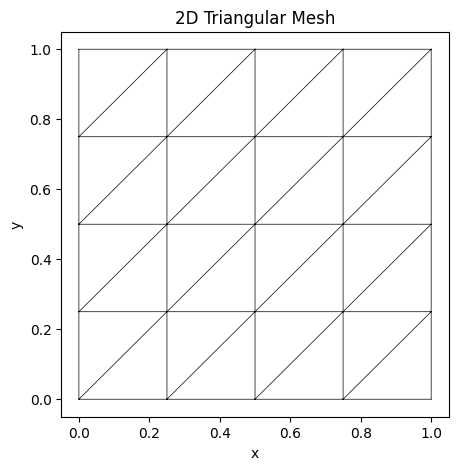

In [29]:
# Step 4: Create a triangular mesh

# Install scikit-fem
%pip -q install scikit-fem

# Import the required libraries
from skfem import MeshTri
from skfem.visuals.matplotlib import draw
import matplotlib.pyplot as plt

# Create the triangular mesh
mesh = MeshTri.init_tensor(
    np.linspace(0, 1, 5),
    np.linspace(0, 1, 5)
)

# Print mesh information
print("Number of vertices:", mesh.p.shape[1])
print("Number of triangles:", mesh.t.shape[1])

# Display the mesh
fig, ax = plt.subplots(figsize=(5, 5))

draw(mesh, ax=ax)

ax.set_title("2D Triangular Mesh")
ax.set_xlabel("x")
ax.set_ylabel("y")

plt.show()

### Result

I created a triangular mesh of the unit square using scikit-fem. The mesh contains 25 vertices and 32 triangular elements.

The plot shows that the unit square is divided into 16 small squares, with each square split into two triangles. The mesh covers the domain as expected.

I will use this mesh in the next steps to define the flux and pressure finite element spaces.


## 5. Defining RT0 and P0 Finite Element Spaces

In this step, I will define the finite element spaces for flux and pressure on the triangular mesh.

I will use:

- RT0 (Raviart-Thomas) elements for the fluid flux.
- P0 (piecewise constant) elements for the pressure.

RT0 is used to approximate the flux in the H(div) space, while P0 is used to approximate the pressure in the L² space.

For RT0 elements, the degrees of freedom are associated with the mesh edges. For P0 elements, each triangle has one pressure degree of freedom.

I will use scikit-fem to define these spaces and check their number of degrees of freedom.


In [30]:
# Step 5: Define RT0 and P0 finite element spaces

from skfem import Basis, ElementTriRT0, ElementTriP0

# Define RT0 space for flux
flux_basis = Basis(mesh, ElementTriRT0())

# Define P0 space for pressure
pressure_basis = Basis(mesh, ElementTriP0())

# Count the degrees of freedom
flux_dofs = flux_basis.N
pressure_dofs = pressure_basis.N

# Print the results
print("RT0 flux degrees of freedom:", flux_dofs)
print("P0 pressure degrees of freedom:", pressure_dofs)
print("Total degrees of freedom:", flux_dofs + pressure_dofs)


RT0 flux degrees of freedom: 56
P0 pressure degrees of freedom: 32
Total degrees of freedom: 88


### Result

I defined the RT0 space for flux and the P0 space for pressure using scikit-fem.

The RT0 space has 56 degrees of freedom, and the P0 space has 32 degrees of freedom. The total number of unknowns is 88.

These values agree with the mesh structure. I will use these spaces to assemble the mixed Darcy saddle-point system in the next steps.


## 6. Assembly of the Mixed Darcy Saddle-Point Matrix

In this step, I will assemble the matrices for the mixed Darcy problem using the RT0 and P0 finite element spaces.

For K = 1, the mixed weak formulation is:

$$
\int_\Omega \mathbf{q}\cdot\mathbf{v}\,d\Omega
-
\int_\Omega p\,\nabla\cdot\mathbf{v}\,d\Omega
=0
$$

$$
\int_\Omega (\nabla\cdot\mathbf{q})w\,d\Omega
=
\int_\Omega fw\,d\Omega
$$

Here, v is a flux test function and w is a pressure test function. The boundary pressure is zero.

I will define the flux matrix A and the divergence matrix D. I will then use B = -D to construct the symmetric saddle-point matrix:

$$
G=
\begin{bmatrix}
A & B^T\\
B & 0
\end{bmatrix}
$$

I will check the matrix sizes and symmetry before solving the linear system.


In [31]:
# Step 6: Assemble the mixed Darcy matrices

from skfem import BilinearForm, asm
from skfem.helpers import dot, div
from scipy.sparse import bmat

# Use the same integration order for both spaces
flux_basis = Basis(mesh, ElementTriRT0(), intorder=2)
pressure_basis = Basis(mesh, ElementTriP0(), intorder=2)

# Define the flux matrix
@BilinearForm
def flux_form(q, v, w):
    return dot(q, v)

# Define the divergence matrix
@BilinearForm
def divergence_form(q, r, w):
    return div(q) * r

# Assemble the matrices
A = asm(flux_form, flux_basis)
D = asm(divergence_form, flux_basis, pressure_basis)

# Use the sign convention B = -D
B = -D

# Construct the saddle-point matrix
G = bmat([[A, B.T],
          [B, None]], format="csr")

# Check matrix sizes
print("A matrix shape:", A.shape)
print("B matrix shape:", B.shape)
print("Full saddle-point matrix shape:", G.shape)

# Check symmetry
is_symmetric = np.allclose(G.toarray(), G.toarray().T)
print("Is the full matrix symmetric?", is_symmetric)


A matrix shape: (56, 56)
B matrix shape: (32, 56)
Full saddle-point matrix shape: (88, 88)
Is the full matrix symmetric? True


### Result

I assembled the flux and divergence matrices using the RT0 and P0 finite element spaces.

The flux matrix A has size 56 × 56, and the divergence matrix B has size 32 × 56. After combining the blocks, I obtained an 88 × 88 saddle-point matrix.

I also checked the symmetry of the full matrix, and the result was True. The matrix dimensions are consistent with the degrees of freedom calculated earlier.

The next step is to construct the right-hand-side vector and check the numerical solution.


## 7. Assembly of the Right-Hand-Side Vector

In this step, I will assemble the right-hand-side vector for the mixed Darcy system.

The source term is:

$$
f(x,y)=2\pi^2\sin(\pi x)\sin(\pi y)
$$

I will use the P0 pressure space to assemble the source vector:

$$
F_i=\int_\Omega f w_i\,d\Omega
$$

Since the boundary pressure is zero and I used B = -D in the previous step, the full right-hand-side vector is:

$$
b=
\begin{bmatrix}
0\\
-F
\end{bmatrix}
$$

I will check the vector sizes before solving the linear system.


In [32]:
# Step 7: Assemble the right-hand-side vector

from skfem import LinearForm

# Define the source term contribution
@LinearForm
def source_form(v, w):
    x = w.x[0]
    y = w.x[1]

    f = source_term(x, y)

    return f * v

# Assemble the source vector
F = asm(source_form, pressure_basis)

# Create the zero vector for the first block
zero_vector = np.zeros(flux_basis.N)

# Combine both parts of the right-hand side
b = np.concatenate((zero_vector, -F))

# Print the results
print("Source vector shape:", F.shape)
print("Full RHS vector shape:", b.shape)
print("First block is zero:", np.allclose(zero_vector, 0))
print("Sum of source vector:", np.sum(F))


Source vector shape: (32,)
Full RHS vector shape: (88,)
First block is zero: True
Sum of source vector: 7.998353020415598


### Result
I assembled the right-hand-side vector for the mixed Darcy problem.

The source vector has 32 entries, and the complete right-hand-side vector has 88 entries. The first block is zero because the prescribed boundary pressure is zero.

The sum of the source vector is 7.998353, which is close to the exact integral value of 8. The small difference comes from numerical integration.

The vector dimensions are correct, and I can now use the assembled matrix and right-hand-side vector to solve the system.

## 8. Solving the Mixed Darcy System Using a Direct Solver

In this step, I will solve the mixed Darcy saddle-point system using the direct solver from SciPy.

The linear system is:

$$
Gz=b
$$

where G is the saddle-point matrix, z contains the unknown flux and pressure coefficients, and b is the right-hand-side vector.

I will use the `spsolve` function to calculate the numerical solution.

After solving the system, I will separate the flux and pressure coefficients and calculate the residual:

$$
r=b-Gz
$$

I will also check the relative residual:

$$
\text{Relative residual}=
\frac{\|b-Gz\|_2}{\|b\|_2}
$$

This will help me check how accurately the direct solver solves the assembled linear system.


In [33]:
# Step 8: Solve the mixed Darcy system

from scipy.sparse.linalg import spsolve

# Solve the linear system Gz = b
z = spsolve(G, b)

# Separate flux and pressure coefficients
q_numerical = z[:flux_basis.N]
p_numerical = z[flux_basis.N:]

# Calculate the residual
residual = b - G @ z

# Calculate residual norms
residual_norm = np.linalg.norm(residual)
relative_residual = residual_norm / np.linalg.norm(b)

# Print results
print("Number of flux coefficients:", len(q_numerical))
print("Number of pressure coefficients:", len(p_numerical))
print("All solution values are finite:", np.all(np.isfinite(z)))
print("Residual norm:", residual_norm)
print("Relative residual:", relative_residual)


Number of flux coefficients: 56
Number of pressure coefficients: 32
All solution values are finite: True
Residual norm: 1.2548515289041793e-15
Relative residual: 7.443571321860165e-16


### Result

I solved the mixed Darcy saddle-point system using SciPy's direct solver.

The solution contains 56 flux coefficients and 32 pressure coefficients. All the calculated values are finite.

The residual norm is approximately 1.25 × 10⁻¹⁵, and the relative residual is approximately 7.44 × 10⁻¹⁶.

These small residuals show that the direct solver solved the assembled linear system accurately.

The next step is to compare the numerical pressure and flux with the exact solution to check the accuracy of the finite element approximation.

## 9. Comparing Numerical and Exact Pressure

In this step, I will compare the numerical pressure obtained from the direct solver with the exact pressure solution.

The exact pressure is:

$$
p(x,y)=\sin(\pi x)\sin(\pi y)
$$

Since I am using P0 elements, the numerical pressure is constant inside each triangle.

I will calculate the exact pressure at the center of each triangle and compare it with the numerical pressure.

The pressure error is:

$$
e_i=p_{h,i}-p(x_i,y_i)
$$

I will calculate the maximum absolute error and the root mean square error (RMSE) to get an initial idea of the pressure accuracy.


In [34]:
# Step 9: Compare numerical and exact pressure

# Find the center of each triangle
x_center = np.mean(mesh.p[0, mesh.t], axis=0)
y_center = np.mean(mesh.p[1, mesh.t], axis=0)

# Calculate exact pressure at triangle centers
p_exact = exact_pressure(x_center, y_center)

# Calculate the pressure difference
pressure_error = p_numerical - p_exact

# Calculate error measurements
max_error = np.max(np.abs(pressure_error))
rmse = np.sqrt(np.mean(pressure_error**2))

# Print results
print("Number of triangles:", len(p_exact))
print("Number of numerical pressure values:", len(p_numerical))

print("Maximum absolute pressure error:", max_error)
print("Pressure RMSE:", rmse)

# Compare pressure in the first triangle
print("Numerical pressure (first triangle):", p_numerical[0])
print("Exact pressure (first triangle center):", p_exact[0])

Number of triangles: 32
Number of numerical pressure values: 32
Maximum absolute pressure error: 0.04717656250041302
Pressure RMSE: 0.02696422967694719
Numerical pressure (first triangle): 0.13969860678442114
Exact pressure (first triangle center): 0.12940952255126034


### Result

I compared the numerical pressure from the direct solver with the exact pressure at the center of each triangle.

The maximum absolute pressure error was approximately 0.04718, and the RMSE was approximately 0.02696.

For the first triangle, the numerical pressure was 0.13970, while the exact pressure at its center was 0.12941.

The numerical pressure is close to the exact pressure, but there are some differences because I am using a coarse mesh and P0 elements.

This is an initial accuracy check. I will need to refine the mesh and study how the error changes to check the convergence of the finite element solution.

## 10. Comparing Numerical and Exact Flux

In this step, I will compare the numerical flux from the direct solver with the exact flux.

The exact flux components are:

$$
q_x=-\pi\cos(\pi x)\sin(\pi y)
$$

$$
q_y=-\pi\sin(\pi x)\cos(\pi y)
$$

I will evaluate the numerical and exact flux at integration points inside the triangles.

I will calculate the L² flux error using numerical integration:

$$
\|\mathbf{q}_h-\mathbf{q}\|_{L^2(\Omega)}
=
\sqrt{\int_\Omega |\mathbf{q}_h-\mathbf{q}|^2\,d\Omega}
$$

I will also calculate the relative L² error to check how close the numerical flux is to the exact flux.

This will help me check the flux approximation before studying mesh refinement.

In [35]:
# Step 10: Compare numerical and exact flux

# Evaluate numerical flux at integration points
q_values = flux_basis.interpolate(q_numerical).value

# Get the coordinates of integration points
points = flux_basis.global_coordinates()

# Calculate exact flux at the same points
qx_exact, qy_exact = exact_flux(points[0], points[1])

# Calculate the differences
error_x = q_values[0] - qx_exact
error_y = q_values[1] - qy_exact

# Calculate the squared flux error
error_squared = error_x**2 + error_y**2

# Calculate the L2 flux error using numerical integration
flux_l2_error = np.sqrt(np.sum(error_squared * flux_basis.dx))

# Calculate the L2 norm of the exact flux
exact_squared = qx_exact**2 + qy_exact**2
exact_l2_norm = np.sqrt(np.sum(exact_squared * flux_basis.dx))

# Calculate relative error
relative_flux_error = flux_l2_error / exact_l2_norm

# Print results
print("Number of triangles:", mesh.t.shape[1])
print("Numerical flux array shape:", q_values.shape)
print("L2 flux error:", flux_l2_error)
print("Relative L2 flux error:", relative_flux_error)


Number of triangles: 32
Numerical flux array shape: (2, 32, 3)
L2 flux error: 0.4998150209144782
Relative L2 flux error: 0.22499580919485498


### Result

I compared the numerical flux with the exact flux using the RT0 finite element solution.

The L² flux error was approximately 0.49982, and the relative L² error was 0.2250 (22.50%).

This shows that there is still a noticeable difference between the numerical and exact flux on the current mesh of 32 triangles.

I will need to refine the mesh and check whether the error decreases. This will help me understand the accuracy and convergence of the RT0 approximation.

## 11. Mesh Refinement and Convergence Study

In this step, I will study how the numerical errors change when I refine the mesh.

I will solve the same mixed Darcy problem using three meshes with 32, 128, and 512 triangles.

For each mesh, I will calculate:

- Pressure RMSE at the triangle centers.
- L² error of the numerical flux.

I want to check whether the errors decrease as the mesh becomes finer. This will help me understand the convergence of the RT0-P0 finite element approximation.

In [36]:
# Step 11: Mesh refinement study

# Try three different mesh sizes
mesh_sizes = [4, 8, 16]

for n in mesh_sizes:

    # Create a new triangular mesh
    mesh_new = MeshTri.init_tensor(
        np.linspace(0, 1, n + 1),
        np.linspace(0, 1, n + 1)
    )

    # Define RT0 and P0 spaces
    qb = Basis(mesh_new, ElementTriRT0(), intorder=2)
    pb = Basis(mesh_new, ElementTriP0(), intorder=2)

    # Assemble the matrices
    A_new = asm(flux_form, qb)
    D_new = asm(divergence_form, qb, pb)

    G_new = bmat([
        [A_new, -D_new.T],
        [-D_new, None]
    ], format="csr")

    # Assemble the right-hand side
    F_new = asm(source_form, pb)
    b_new = np.concatenate((np.zeros(qb.N), -F_new))

    # Solve the system
    z_new = spsolve(G_new, b_new)

    # Separate flux and pressure
    q_num = z_new[:qb.N]
    p_num = z_new[qb.N:]

    # Calculate pressure RMSE
    xc = np.mean(mesh_new.p[0, mesh_new.t], axis=0)
    yc = np.mean(mesh_new.p[1, mesh_new.t], axis=0)

    p_exact_new = exact_pressure(xc, yc)
    pressure_rmse = np.sqrt(np.mean((p_num - p_exact_new)**2))

    # Calculate flux L2 error
    q_values = qb.interpolate(q_num).value
    points = qb.global_coordinates()

    qx_exact, qy_exact = exact_flux(points[0], points[1])

    flux_difference = ((q_values[0] - qx_exact)**2
                       + (q_values[1] - qy_exact)**2)

    flux_error = np.sqrt(np.sum(flux_difference * qb.dx))

    # Display results
    print("Mesh divisions:", n, "x", n)
    print("Number of triangles:", mesh_new.t.shape[1])
    print("Pressure RMSE:", pressure_rmse)
    print("Flux L2 error:", flux_error)
    print("-----------------------------")

Mesh divisions: 4 x 4
Number of triangles: 32
Pressure RMSE: 0.02696422967694719
Flux L2 error: 0.4998150209144782
-----------------------------
Mesh divisions: 8 x 8
Number of triangles: 128
Pressure RMSE: 0.006957047944988452
Flux L2 error: 0.25136678325803274
-----------------------------
Mesh divisions: 16 x 16
Number of triangles: 512
Pressure RMSE: 0.0017518385640823255
Flux L2 error: 0.12585665382137717
-----------------------------


### Result

I solved the mixed Darcy problem using three meshes with 32, 128, and 512 triangles.

The pressure RMSE decreased from 0.026964 to 0.001752, while the flux L² error decreased from 0.499815 to 0.125857.

The results show that both errors decrease as the mesh becomes finer.

The observed convergence order is approximately 2 for the pressure RMSE measured at triangle centers and approximately 1 for the flux L² error.

These results are encouraging, but the pressure RMSE is not the same as the full L² pressure error. I will need further checks to verify the finite element solution more completely.

## 12. Verification of Mass Conservation

In this step, I will check whether the numerical flux satisfies the mass conservation equation.

The Darcy flow equation is:

$$
\nabla\cdot\mathbf{q}=f
$$

In the mixed finite element system, the discrete form is:

$$
Dq_h=F
$$

Here, D is the divergence matrix, q_h contains the numerical flux coefficients, and F is the source vector.

I will compare the two sides of this equation for each triangle.

The local mass balance error is:

$$
e=Dq_h-F
$$

I will calculate the maximum absolute error and the error norm to check how well mass conservation is satisfied.


In [37]:
# Step 12: Verify mass conservation

# Calculate the divergence contribution
numerical_divergence = D @ q_numerical

# Calculate the local mass balance error
mass_error = numerical_divergence - F

# Calculate the error measurements
max_mass_error = np.max(np.abs(mass_error))
mass_error_norm = np.linalg.norm(mass_error)

# Check mass conservation
mass_conserved = np.allclose(numerical_divergence, F, atol=1e-10)

# Print results
print("Number of triangles:", len(F))
print("Maximum mass balance error:", max_mass_error)
print("Mass balance error norm:", mass_error_norm)
print("Mass conservation satisfied:", mass_conserved)

# Check the first triangle
print("First triangle divergence:", numerical_divergence[0])
print("First triangle source:", F[0])

Number of triangles: 32
Maximum mass balance error: 7.216449660063518e-16
Mass balance error norm: 1.0502343149091646e-15
Mass conservation satisfied: True
First triangle divergence: 0.08587022378195558
First triangle source: 0.08587022378195552


### Result

I checked the mass conservation equation using the numerical flux from the direct solver.

The maximum mass balance error was approximately 7.22 × 10⁻¹⁶, and the error norm was approximately 1.05 × 10⁻¹⁵.

The integrated divergence and source contribution were almost equal for every triangle. This shows that the numerical solution satisfies the discrete mass conservation equation within numerical precision.

This check is important because local mass conservation is one of the main reasons for using RT0 elements in mixed Darcy problems.

## 13. Final Review and Summary

In this notebook, I implemented a two-dimensional mixed Darcy problem using RT0 elements for flux and P0 elements for pressure.

I assembled the saddle-point matrix and solved the system using SciPy's direct solver.

I also compared the numerical solution with the exact solution, studied mesh refinement, and checked local mass conservation.

In this final step, I will collect the main numerical results in one place.

These results will be useful as a reference when I start testing iterative solvers and preconditioners.

In [38]:
# Step 13: Summary of the first notebook

print("MIXED DARCY PROBLEM - SUMMARY")
print("_________________________________________________")

# Problem size
print("Number of triangles:", mesh.t.shape[1])
print("Flux degrees of freedom:", flux_basis.N)
print("Pressure degrees of freedom:", pressure_basis.N)
print("Saddle-point matrix shape:", G.shape)

print("_________________________________________________")

# Direct solver
print("Relative residual:", relative_residual)

# Numerical accuracy
print("Pressure RMSE:", rmse)
print("Flux L2 error:", flux_l2_error)

# Mass conservation
print("Maximum mass balance error:", max_mass_error)

print("_________________________________________________")

# Final basic checks
print("Matrix is symmetric:",
      np.allclose(G.toarray(), G.toarray().T))

print("Solution values are finite:",
      np.all(np.isfinite(z)))

print("Mass conservation satisfied:",
      np.allclose(D @ q_numerical, F, atol=1e-10))

MIXED DARCY PROBLEM - SUMMARY
_________________________________________________
Number of triangles: 32
Flux degrees of freedom: 56
Pressure degrees of freedom: 32
Saddle-point matrix shape: (88, 88)
_________________________________________________
Relative residual: 7.443571321860165e-16
Pressure RMSE: 0.02696422967694719
Flux L2 error: 0.4998150209144782
Maximum mass balance error: 7.216449660063518e-16
_________________________________________________
Matrix is symmetric: True
Solution values are finite: True
Mass conservation satisfied: True


### Result

I reviewed the main results from my mixed Darcy finite element notebook.

The original mesh has 32 triangles, 56 flux degrees of freedom, and 32 pressure degrees of freedom. The assembled saddle-point matrix has a size of 88 × 88 and is symmetric.

The direct solver produced a relative residual of approximately 7.44 × 10⁻¹⁶.

The pressure RMSE was approximately 0.026964, and the flux L² error was approximately 0.499815 on the original mesh. Both errors decreased during the mesh refinement study.

The maximum mass balance error was approximately 7.22 × 10⁻¹⁶, showing that the discrete local mass conservation equation was satisfied within numerical precision.

These checks provide a useful starting point for my next work on iterative solvers and preconditioners.